In [3]:
from pathlib import Path

DIR_VIDEOS = Path(r"C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\videos")
DIR_FRAMES = Path(r"C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames")
DIR_KEYPOINTS = Path(r"C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints")
DIR_DATASET = Path(r"C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\split_dataset")

DIR_FRAMES.mkdir(parents=True, exist_ok=True)
DIR_KEYPOINTS.mkdir(parents=True, exist_ok=True)
DIR_DATASET.mkdir(parents=True, exist_ok=True)

VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv"}


# 1. Get frames

In [4]:
import cv2

video_paths = sorted(
    p for p in DIR_VIDEOS.rglob("*") if p.suffix.lower() in VIDEO_EXTENSIONS
)
print(f"Found {len(video_paths)} videos in {DIR_VIDEOS}")

for video_path in video_paths:
    out_dir = DIR_FRAMES / video_path.relative_to(DIR_VIDEOS).with_suffix("")
    out_dir.mkdir(parents=True, exist_ok=True)

    cap = cv2.VideoCapture(str(video_path))
    frame_idx = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame = cv2.resize(frame, None, fx=0.75, fy=0.75, interpolation=cv2.INTER_AREA)
        frame_path = out_dir / f"{video_path.stem}_{frame_idx:05d}.jpg"
        cv2.imwrite(str(frame_path), frame, [cv2.IMWRITE_JPEG_QUALITY, 80])
        frame_idx += 1
    cap.release()

    print(f"{video_path.relative_to(DIR_VIDEOS)}: saved {frame_idx} frames -> {out_dir}")


Found 300 videos in C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\videos
P_06\a_veces\a_veces05_4.mp4: saved 61 frames -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames\P_06\a_veces\a_veces05_4
P_06\a_veces\a_veces06_1.mp4: saved 62 frames -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames\P_06\a_veces\a_veces06_1
P_06\a_veces\a_veces06_10.mp4: saved 45 frames -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames\P_06\a_veces\a_veces06_10
P_06\a_veces\a_veces06_2.mp4: saved 74 frames -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames\P_06\a_veces\a_veces06_2
P_06\a_veces\a_veces06_3.mp4: saved 57 frames -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames\P_06\a_veces\a_veces06_3
P_06\a_veces\a_veces06_5.mp4: saved 71 frames -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\frames\P_06\a_veces\a_veces06_5
P_06\a_veces\a_v

# 2a. Keypoint definitions

In [5]:
import numpy as np
import mediapipe as mp
import cv2


mp_holistic = mp.solutions.holistic

# Pose: landmarks 11-22 only -- shoulders, elbows, wrists and the hand stubs.
#
# 23-32 are hips, knees, ankles, heels and feet. The signer is framed from
# roughly the waist up, so MediaPipe does not observe them -- it extrapolates
# them off the bottom of the image. Measured over the recorded clips: 100% of
# those landmarks fall below y=1.0 (the image edge), reaching y=2.8 in a
# coordinate space that is supposed to be [0,1], and their confidence collapses
# accordingly: visibility averages 0.025 at the hips, 0.001 at the knees and
# 0.000 at the ankles and feet, against 1.000 at the shoulders.
#
# 0-10 are the nose, eyes, ears and mouth corners. They overlap the face mesh
# below and describe it far more coarsely: one nose point where the face mesh
# has a tip and a bridge, two mouth corners where it has corners plus both lips.
# The face mesh is the head; the pose contributes the body the hands hang off.
#
# Both groups are dropped here rather than downstream, so nothing is extracted,
# normalized, padded and stored only to be sliced away before the model sees it.
POSE_LANDMARK_IDS = list(range(11, 23))

# Face: 21 of MediaPipe's 468 mesh points.
#
# Keeping the full mesh would make the face 1404 of the vector's values and
# swamp the hands, which carry most of the signal. These points are the ones
# that move meaningfully in sign language -- the non-manual markers.
#
# Note MediaPipe names sides from the signer's perspective, so "right" here is
# the side that appears on the left of the image.
FACE_LANDMARK_IDS = [
    # Mouth: corners give width, upper/lower lip give aperture. Both are needed
    # -- corners alone cannot tell an open mouth from a closed one, and mouthing
    # is grammatical in sign language.
    61, 291,    # mouth corners: right / left
    0, 17,      # lips: upper / lower centre
    # Eyes: corners give shape, eyelid centres give aperture (squint, wide eyes).
    33, 263,    # outer corners: right / left
    133, 362,   # inner corners: right / left
    159, 145,   # right eye: upper / lower eyelid
    386, 374,   # left eye: upper / lower eyelid
    # Eyebrows: raised for yes/no questions, furrowed for wh-questions in most
    # sign languages. Inner ends move most.
    105, 334,   # mid-brow: right / left
    107, 336,   # inner ends: right / left
    # Face frame: gives the rest of the points something to move relative to,
    # and captures head tilt / nod / shake.
    1, 6,       # nose: tip / bridge
    10,         # top of face
    9,          # forehead
    152,        # chin
]

N_POSE = len(POSE_LANDMARK_IDS)   # 23 landmarks x (x, y, z, visibility)
N_FACE = len(FACE_LANDMARK_IDS)   # 21 landmarks x (x, y, z)
N_HAND = 21                       # 21 landmarks x (x, y, z), per hand

# Column layout of one frame's feature vector. Derived from the counts above so
# that changing the landmark lists above updates every downstream cell.
POSE = slice(0, N_POSE * 4)
FACE = slice(POSE.stop, POSE.stop + N_FACE * 3)
LEFT_HAND = slice(FACE.stop, FACE.stop + N_HAND * 3)
RIGHT_HAND = slice(LEFT_HAND.stop, LEFT_HAND.stop + N_HAND * 3)
FEATURE_DIM = RIGHT_HAND.stop

# Positions within POSE_LANDMARK_IDS, looked up by MediaPipe id so they stay
# correct if the list above changes.
L_SHOULDER = POSE_LANDMARK_IDS.index(11)
R_SHOULDER = POSE_LANDMARK_IDS.index(12)


def extract_keypoints(results):
    if results.pose_landmarks:
        pose_lms = results.pose_landmarks.landmark
        pose = np.array(
            [
                [pose_lms[i].x, pose_lms[i].y, pose_lms[i].z, pose_lms[i].visibility]
                for i in POSE_LANDMARK_IDS
            ]
        ).flatten()
    else:
        pose = np.zeros(N_POSE * 4)

    if results.face_landmarks:
        face_lms = results.face_landmarks.landmark
        face = np.array(
            [[face_lms[i].x, face_lms[i].y, face_lms[i].z] for i in FACE_LANDMARK_IDS]
        ).flatten()
    else:
        face = np.zeros(N_FACE * 3)

    if results.left_hand_landmarks:
        lh = np.array([[lm.x, lm.y, lm.z] for lm in results.left_hand_landmarks.landmark]).flatten()
    else:
        lh = np.zeros(N_HAND * 3)

    if results.right_hand_landmarks:
        rh = np.array([[lm.x, lm.y, lm.z] for lm in results.right_hand_landmarks.landmark]).flatten()
    else:
        rh = np.zeros(N_HAND * 3)

    return np.concatenate([pose, face, lh, rh])


print(f"feature vector: {FEATURE_DIM} values "
      f"(pose {N_POSE}x4, face {N_FACE}x3, hands 2x{N_HAND}x3)")


feature vector: 237 values (pose 12x4, face 21x3, hands 2x21x3)


# 2b. Extract keypoints

In [6]:
import cv2

frame_dirs = sorted({p.parent for p in DIR_FRAMES.rglob("*.jpg")})

with mp_holistic.Holistic(static_image_mode=True) as holistic:
    for frame_dir in frame_dirs:
        out_dir = DIR_KEYPOINTS / frame_dir.relative_to(DIR_FRAMES)
        out_dir.mkdir(parents=True, exist_ok=True)

        frame_paths = sorted(frame_dir.glob("*.jpg"))
        for frame_path in frame_paths:
            image = cv2.imread(str(frame_path))
            image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            results = holistic.process(image_rgb)

            keypoints = extract_keypoints(results)
            np.save(out_dir / f"{frame_path.stem}.npy", keypoints)

        print(f"{frame_dir.relative_to(DIR_FRAMES)}: saved {len(frame_paths)} keypoint files -> {out_dir}")

c:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\signapp_thesis\.venv\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


P_06\a_veces\a_veces05_4: saved 61 keypoint files -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces05_4
P_06\a_veces\a_veces06_1: saved 62 keypoint files -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces06_1
P_06\a_veces\a_veces06_10: saved 45 keypoint files -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces06_10
P_06\a_veces\a_veces06_2: saved 74 keypoint files -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces06_2
P_06\a_veces\a_veces06_3: saved 57 keypoint files -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces06_3
P_06\a_veces\a_veces06_5: saved 71 keypoint files -> C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces06_5
P_06\a_veces\a_veces06_6: saved 54 keypoint files -> C:\Users\B13VE\

# 2.1b GRAFICAR KEYPOINTS - CHECKING

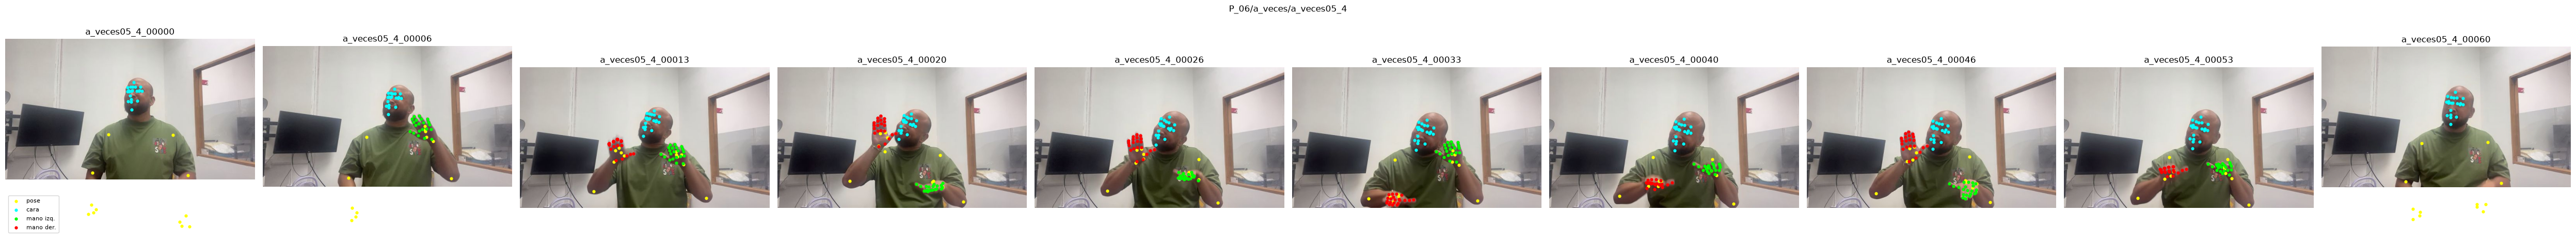

In [9]:
import matplotlib.pyplot as plt

CLIP = r"C:\Users\B13VE\Desktop\docs dri_utp\01_RESEARCH\0_frame_extraction\keypoints\P_06\a_veces\a_veces05_4"  # None = primer clip; o una ruta como "P_01/hola/clip_01"
N_FRAMES = 10

clip_dir = (DIR_KEYPOINTS / CLIP if CLIP
            else sorted({p.parent for p in DIR_KEYPOINTS.rglob("*.npy")})[0])
kp_paths = sorted(clip_dir.glob("*.npy"))
elegidos = [kp_paths[i] for i in np.linspace(0, len(kp_paths) - 1, N_FRAMES).astype(int)]

PARTES = [("pose", POSE, 4, "yellow"), ("cara", FACE, 3, "cyan"),
          ("mano izq.", LEFT_HAND, 3, "lime"), ("mano der.", RIGHT_HAND, 3, "red")]

fig, axes = plt.subplots(1, N_FRAMES, figsize=(5 * N_FRAMES, 5))
for ax, kp_path in zip(axes, elegidos):
    kp = np.load(kp_path)

    img_path = DIR_FRAMES / clip_dir.relative_to(DIR_KEYPOINTS) / f"{kp_path.stem}.jpg"
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    ax.imshow(img)

    for nombre, bloque, valores, color in PARTES:
        pts = kp[bloque].reshape(-1, valores)[:, :3]
        pts = pts[(pts != 0).any(axis=1)]            # quita los no detectados
        ax.scatter(pts[:, 0] * w, pts[:, 1] * h, s=12, c=color, label=nombre)

    ax.set_title(kp_path.stem)
    ax.axis("off")

axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle(clip_dir.relative_to(DIR_KEYPOINTS).as_posix())
plt.tight_layout()
plt.show()

# 3. Split dataset

In [16]:
import json
import random
from collections import defaultdict

import pandas as pd

SEED = 42
RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}

# One sequence = one clip directory holding that clip's per-frame .npy files.
# Splitting whole clips (never individual frames) keeps near-identical frames
# from the same recording out of two different splits.
sequence_dirs = sorted({p.parent for p in DIR_KEYPOINTS.rglob("*.npy")})

clips_by_label = defaultdict(list)
for seq_dir in sequence_dirs:
    clips_by_label[seq_dir.parent.name].append(seq_dir)

rng = random.Random(SEED)
rows = []

# Stratified split, so every class keeps the same train/val/test proportions.
# With 10 clips per class the val/test shares are fractional (1.5 clips), so the
# spare clip goes to whichever split is furthest below its target share of
# everything seen so far. That keeps the dataset as a whole at 70/15/15 instead
# of letting the rounding always favour the same split.
assigned = {name: 0 for name in RATIOS}
n_seen = 0

for label in sorted(clips_by_label):
    clips = clips_by_label[label]
    rng.shuffle(clips)
    n_seen += len(clips)

    counts = {name: int(len(clips) * ratio) for name, ratio in RATIOS.items()}
    for _ in range(len(clips) - sum(counts.values())):
        behind = max(RATIOS, key=lambda s: RATIOS[s] * n_seen - (assigned[s] + counts[s]))
        counts[behind] += 1

    start = 0
    for name in RATIOS:
        for clip_dir in clips[start:start + counts[name]]:
            rows.append(
                {
                    "clip": clip_dir.relative_to(DIR_KEYPOINTS).as_posix(),
                    "label": label,
                    "n_frames": len(list(clip_dir.glob("*.npy"))),
                    "split": name,
                }
            )
        assigned[name] += counts[name]
        start += counts[name]

labels = sorted(clips_by_label)
splits_df = pd.DataFrame(rows).sort_values(["split", "label", "clip"]).reset_index(drop=True)
splits_df.to_csv(DIR_DATASET / "splits.csv", index=False)

# Provenance: everything needed to reproduce this exact split.
config = {
    "seed": SEED,
    "ratios": RATIOS,
    "unit": "clip",
    "stratified_by": "label",
    "signer_independent": False,
    "keypoints_dir": str(DIR_KEYPOINTS),
    "keypoint_dim": 291,
    "labels": labels,
    "n_clips": len(splits_df),
    "counts": {name: int(n) for name, n in splits_df["split"].value_counts().items()},
}
(DIR_DATASET / "split_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

for name in RATIOS:
    subset = splits_df[splits_df["split"] == name]
    per_class = subset["label"].value_counts().reindex(labels).to_dict()
    print(f"{name:5s}: {len(subset):3d} clips ({len(subset) / len(splits_df):.0%})  {per_class}")

print(f"\n{len(splits_df)} clips across {len(labels)} classes -> {DIR_DATASET / 'splits.csv'}")

train:  70 clips (70%)  {'a_veces': 7, 'buenos_dias': 7, 'como_se_dice': 7, 'cual_es_tu_nombre': 7, 'cuidado': 7, 'de_nada': 7, 'encantado_de_conocerte': 7, 'poco_a_poco': 7, 'por_favor': 7, 'repetir': 7}
val  :  15 clips (15%)  {'a_veces': 2, 'buenos_dias': 1, 'como_se_dice': 2, 'cual_es_tu_nombre': 1, 'cuidado': 2, 'de_nada': 1, 'encantado_de_conocerte': 2, 'poco_a_poco': 1, 'por_favor': 2, 'repetir': 1}
test :  15 clips (15%)  {'a_veces': 1, 'buenos_dias': 2, 'como_se_dice': 1, 'cual_es_tu_nombre': 2, 'cuidado': 1, 'de_nada': 2, 'encantado_de_conocerte': 1, 'poco_a_poco': 2, 'por_favor': 1, 'repetir': 2}

100 clips across 10 classes -> C:\Users\isabe\signapp\split_dataset\splits.csv


# 4. Collapse .npy arrays into matrix

In [17]:
import numpy as np
DIR_SEQUENCES = Path(r"C:\Users\isabe\signapp\sequences")
DIR_SEQUENCES.mkdir(parents=True, exist_ok=True)

splits_df = pd.read_csv(DIR_DATASET / "splits.csv")


# Collapse each clip's per-frame .npy files into a single (n_frames, 291) matrix,
# so training reads 100 files instead of 10,459. Lengths stay as recorded.
for row in splits_df.itertuples():
    frame_paths = sorted((DIR_KEYPOINTS / row.clip).glob("*.npy"))
    sequence = np.stack([np.load(p) for p in frame_paths]).astype(np.float32)
    assert len(sequence) == row.n_frames, f"{row.clip}: {len(sequence)} != {row.n_frames}"

    out_path = (DIR_SEQUENCES / row.clip).with_suffix(".npy")
    out_path.parent.mkdir(parents=True, exist_ok=True)
    np.save(out_path, sequence)

print(f"{len(splits_df)} sequences -> {DIR_SEQUENCES}")
print(f"lengths: min {splits_df.n_frames.min()}, max {splits_df.n_frames.max()}, "
      f"mean {splits_df.n_frames.mean():.1f}")

100 sequences -> C:\Users\isabe\signapp\sequences
lengths: min 62, max 172, mean 104.6


# 5. Normalize 

In [18]:
DIR_SEQUENCES_NORM = Path(r"C:\Users\isabe\signapp\sequences_normalized")
DIR_SEQUENCES_NORM.mkdir(parents=True, exist_ok=True)

# POSE / FACE / LEFT_HAND / RIGHT_HAND, N_POSE and L_SHOULDER / R_SHOULDER all
# come from the keypoint extraction cell, so changing the landmark lists there
# is enough -- nothing here needs editing.


def normalize_sequence(sequence):
    """Make coordinates independent of where the signer stood.

    Every frame is recentred on the mid-shoulder point and divided by the
    shoulder width, so the same sign gives the same numbers whether the signer
    is near or far, left or right of frame. Landmarks MediaPipe did not detect
    are left at zero instead of being shifted to some arbitrary position.
    """
    out = sequence.copy()
    n = len(out)

    pose = out[:, POSE].reshape(n, N_POSE, 4)
    left, right = pose[:, L_SHOULDER, :2], pose[:, R_SHOULDER, :2]
    center = (left + right) / 2.0
    scale = np.linalg.norm(left - right, axis=1)
    scale[scale == 0] = 1.0  # no pose in this frame: leave it untouched

    for block, stride in [(POSE, 4), (FACE, 3), (LEFT_HAND, 3), (RIGHT_HAND, 3)]:
        points = out[:, block].reshape(n, -1, stride).copy()
        detected = (points[..., :3] != 0).any(-1)[..., None]

        shifted = points[..., :3].copy()
        shifted[..., 0] -= center[:, None, 0]
        shifted[..., 1] -= center[:, None, 1]
        shifted /= scale[:, None, None]

        points[..., :3] = np.where(detected, shifted, 0.0)
        out[:, block] = points.reshape(n, -1)

    return out


for row in splits_df.itertuples():
    sequence = np.load((DIR_SEQUENCES / row.clip).with_suffix(".npy"))
    out_path = (DIR_SEQUENCES_NORM / row.clip).with_suffix(".npy")
    out_path.parent.mkdir(parents=True, exist_ok=True)
    np.save(out_path, normalize_sequence(sequence))

print(f"{len(splits_df)} sequences normalized -> {DIR_SEQUENCES_NORM}")

example_clip = splits_df["clip"].iloc[0]
check = np.load((DIR_SEQUENCES_NORM / example_clip).with_suffix(".npy"))
pose_xy = check[:, POSE].reshape(-1, N_POSE, 4)[..., :2]
print(f"example {example_clip}: shape {check.shape}, "
      f"pose x/y now {pose_xy.min():.2f}..{pose_xy.max():.2f} (shoulder widths from mid-shoulder)")

100 sequences normalized -> C:\Users\isabe\signapp\sequences_normalized
example P_09/a_veces/a_veces09_10: shape (112, 237), pose x/y now -1.25..2.81 (shoulder widths from mid-shoulder)


# 6. Padding sequences

In [19]:
# MAX_LEN comes from the manifest, never hardcoded: record more participants,
# re-run, and the padding adapts to the new longest clip on its own.
MAX_LEN = int(splits_df["n_frames"].max())
# FEATURE_DIM comes from the keypoint extraction cell, so it follows the
# landmark lists automatically rather than being restated here.

config = json.loads((DIR_DATASET / "split_config.json").read_text(encoding="utf-8"))
labels = config["labels"]
label_to_index = {label: i for i, label in enumerate(labels)}

# Clips keep their real duration and are zero-padded at the end up to MAX_LEN.
# The padding is not data, so every split also stores the true lengths; the model
# rebuilds the mask from them (np.arange(MAX_LEN) < length) and never reads past
# the end of a clip.
for split in ("train", "val", "test"):
    subset = splits_df[splits_df["split"] == split].reset_index(drop=True)

    X = np.zeros((len(subset), MAX_LEN, FEATURE_DIM), dtype=np.float32)
    y = np.zeros(len(subset), dtype=np.int64)
    lengths = np.zeros(len(subset), dtype=np.int64)

    for i, row in enumerate(subset.itertuples()):
        sequence = np.load((DIR_SEQUENCES_NORM / row.clip).with_suffix(".npy"))
        X[i, :len(sequence)] = sequence
        y[i] = label_to_index[row.label]
        lengths[i] = len(sequence)

    np.savez_compressed(DIR_DATASET / f"{split}.npz", X=X, y=y, lengths=lengths)
    padding = 1 - lengths.sum() / (len(subset) * MAX_LEN)
    print(f"{split:5s}: X {X.shape}  y {y.shape}  {padding:.0%} of timesteps are padding")

config["max_len"] = MAX_LEN
config["feature_dim"] = FEATURE_DIM
config["spatial_normalization"] = "mid-shoulder centred, shoulder-width scaled"
(DIR_DATASET / "split_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print(f"\nMAX_LEN = {MAX_LEN} (derived), written to split_config.json")

train: X (70, 172, 237)  y (70,)  39% of timesteps are padding
val  : X (15, 172, 237)  y (15,)  40% of timesteps are padding
test : X (15, 172, 237)  y (15,)  39% of timesteps are padding

MAX_LEN = 172 (derived), written to split_config.json


# 7. Standarizing

In [20]:
# Per-feature standardization. The statistics come from the training clips only
# -- fitting them on val or test would leak information about the evaluation set.
train = np.load(DIR_DATASET / "train.npz")

train_mask = np.arange(MAX_LEN)[None, :] < train["lengths"][:, None]
real_frames = train["X"][train_mask]  # padding excluded from the statistics

mean = real_frames.mean(axis=0)
std = real_frames.std(axis=0)
std[std == 0] = 1.0  # constant features (e.g. landmarks never detected)

np.savez(DIR_DATASET / "feature_stats.npz", mean=mean, std=std)

for split in ("train", "val", "test"):
    data = np.load(DIR_DATASET / f"{split}.npz")
    X, lengths = data["X"], data["lengths"]

    mask = np.arange(MAX_LEN)[None, :] < lengths[:, None]
    X = np.where(mask[..., None], (X - mean) / std, 0.0).astype(np.float32)

    np.savez_compressed(
        DIR_DATASET / f"{split}_standardized.npz", X=X, y=data["y"], lengths=lengths
    )
    print(f"{split:5s}: mean {X[mask].mean():+.3f}  std {X[mask].std():.3f} (real frames only)")

print(f"\nstatistics from {len(real_frames)} training frames -> feature_stats.npz")

train: mean -0.000  std 1.000 (real frames only)
val  : mean +0.003  std 1.021 (real frames only)
test : mean -0.012  std 1.013 (real frames only)

statistics from 7347 training frames -> feature_stats.npz


# 8. Graph nodes

In [21]:
# Graph node layout.
#
# A GCN needs one uniform (T, V, C) tensor: V nodes, each with the same C
# features. The stored vectors are not uniform -- pose landmarks carry a fourth
# value, visibility, that face and hand landmarks do not have. Dropping it gives
# every node the same three spatial coordinates.
#
# Which landmarks exist at all is decided in section 2, so every node here is a
# landmark the model actually uses. Visibility is the one thing still stored and
# not used: it is 12 columns, and keeping it means the with/without-visibility
# ablation is a change to this slice rather than another extraction run.

N_NODES = N_POSE + N_FACE + 2 * N_HAND  # 12 + 21 + 21 + 21 = 75
N_COORDS = 3                            # x, y, z

# Where each body part sits in the node axis, for building the adjacency matrix
# and for reading results back out per part.
POSE_NODES = slice(0, N_POSE)
FACE_NODES = slice(POSE_NODES.stop, POSE_NODES.stop + N_FACE)
LEFT_HAND_NODES = slice(FACE_NODES.stop, FACE_NODES.stop + N_HAND)
RIGHT_HAND_NODES = slice(LEFT_HAND_NODES.stop, LEFT_HAND_NODES.stop + N_HAND)


def to_nodes(X):
    """(..., FEATURE_DIM) flat vectors -> (..., N_NODES, 3) node coordinates."""
    lead = X.shape[:-1]
    parts = [
        X[..., POSE].reshape(*lead, N_POSE, 4)[..., :3],  # drop visibility
        X[..., FACE].reshape(*lead, N_FACE, 3),
        X[..., LEFT_HAND].reshape(*lead, N_HAND, 3),
        X[..., RIGHT_HAND].reshape(*lead, N_HAND, 3),
    ]
    return np.concatenate(parts, axis=-2)


for split in ("train", "val", "test"):
    data = np.load(DIR_DATASET / f"{split}.npz")
    nodes = to_nodes(data["X"])
    print(f"{split:5s}: {data['X'].shape} -> {nodes.shape}")

print(f"\n{N_NODES} nodes x {N_COORDS} coords: "
      f"pose {POSE_NODES.start}-{POSE_NODES.stop - 1} (landmarks {POSE_LANDMARK_IDS[0]}-{POSE_LANDMARK_IDS[-1]}), "
      f"face {FACE_NODES.start}-{FACE_NODES.stop - 1}, "
      f"left hand {LEFT_HAND_NODES.start}-{LEFT_HAND_NODES.stop - 1}, "
      f"right hand {RIGHT_HAND_NODES.start}-{RIGHT_HAND_NODES.stop - 1}")

train: (70, 172, 237) -> (70, 172, 75, 3)
val  : (15, 172, 237) -> (15, 172, 75, 3)
test : (15, 172, 237) -> (15, 172, 75, 3)

75 nodes x 3 coords: pose 0-11 (landmarks 11-22), face 12-32, left hand 33-53, right hand 54-74


# 9. Skeleton graph

In [22]:
# Skeleton graph.
#
# The topology is a constant -- the same 75 nodes and the same edges for every
# frame of every clip -- so it is built here at runtime from explicit edge lists
# rather than loaded from disk. Keeping it as code means it cannot go stale
# against the landmark lists in section 2: change a landmark there and this cell
# either follows automatically or fails loudly.
#
# Every edge below is anatomical: bones for the body and hands, spatial
# adjacency for the face. No shortcut edges are added to shorten paths or to
# link parts that are not physically attached. Semantic or learned connections
# are a separate approach, to be tested against this one.

# Pose and hands follow the real bone structure, taken from MediaPipe's own
# connection sets so the topology matches the model that produced the points.
# Pose edges are remapped from MediaPipe landmark ids to node indices, which
# also drops any edge touching a landmark not kept in POSE_LANDMARK_IDS.
POSE_LOCAL = {mp_id: i for i, mp_id in enumerate(POSE_LANDMARK_IDS)}
POSE_EDGES = [
    (POSE_LOCAL[a], POSE_LOCAL[b])
    for a, b in mp.solutions.pose.POSE_CONNECTIONS
    if a in POSE_LOCAL and b in POSE_LOCAL
]
HAND_EDGES = sorted(mp.solutions.hands.HAND_CONNECTIONS)

# The face mesh is not a bone structure and we keep only 21 of its 468 points,
# so its edges are defined by hand, in MediaPipe face-mesh ids (the same numbers
# as FACE_LANDMARK_IDS above) and translated to node indices below.
FACE_EDGES_BY_ID = [
    # Mouth, hanging off the chin: chin -> lower lip -> corners -> upper lip.
    (152, 17),
    (17, 61), (17, 291),
    (61, 0), (291, 0),
    # Up the midline: upper lip -> nose tip -> nose bridge.
    (0, 1), (1, 6),
    # Nose bridge out to the inner corner of each eye.
    (6, 133), (6, 362),
    # Each eye as a ring: inner corner -> both eyelids -> outer corner.
    (133, 159), (133, 145), (159, 33), (145, 33),
    (362, 386), (362, 374), (386, 263), (374, 263),
    # Midline continues up: nose bridge -> forehead -> top of face.
    (6, 9), (9, 10),
    # Eyebrows hang off the forehead: forehead -> each mid-brow -> its inner end.
    (9, 105), (9, 334),
    (105, 107), (334, 336),
]

# Bridges between the four parts. Without these the graph is four disconnected
# components and no information can flow from the hands to the body or face.
# The head attaches at the chin, the lowest face point and the one that actually
# sits near the shoulders.
FACE_TO_SHOULDERS = 152          # face-mesh chin
POSE_L_SHOULDER, POSE_R_SHOULDER = 11, 12
HAND_WRIST = 0                   # hand landmark 0 is the wrist, in both hands
POSE_L_WRIST, POSE_R_WRIST = 15, 16


def build_adjacency():
    """Undirected (N_NODES, N_NODES) adjacency, with self-loops."""
    face_index = {mp_id: i for i, mp_id in enumerate(FACE_LANDMARK_IDS)}
    edges = []

    edges += [(POSE_NODES.start + a, POSE_NODES.start + b) for a, b in POSE_EDGES]
    edges += [
        (FACE_NODES.start + face_index[a], FACE_NODES.start + face_index[b])
        for a, b in FACE_EDGES_BY_ID
    ]
    for start in (LEFT_HAND_NODES.start, RIGHT_HAND_NODES.start):
        edges += [(start + a, start + b) for a, b in HAND_EDGES]

    chin = FACE_NODES.start + face_index[FACE_TO_SHOULDERS]
    edges += [
        (chin, POSE_NODES.start + POSE_LOCAL[POSE_L_SHOULDER]),
        (chin, POSE_NODES.start + POSE_LOCAL[POSE_R_SHOULDER]),
        (LEFT_HAND_NODES.start + HAND_WRIST, POSE_NODES.start + POSE_LOCAL[POSE_L_WRIST]),
        (RIGHT_HAND_NODES.start + HAND_WRIST, POSE_NODES.start + POSE_LOCAL[POSE_R_WRIST]),
    ]

    A = np.zeros((N_NODES, N_NODES), dtype=np.float32)
    for i, j in edges:
        A[i, j] = A[j, i] = 1.0
    np.fill_diagonal(A, 1.0)  # self-loops: a node keeps its own features
    return A, edges


def normalize_adjacency(A):
    """Symmetric normalization D^-1/2 A D^-1/2, the standard GCN propagation rule.

    Without it, high-degree nodes (the wrists, which join a hand to an arm)
    would dominate every message-passing step simply by having more neighbours.
    """
    degree = A.sum(axis=1)
    d_inv_sqrt = 1.0 / np.sqrt(degree)
    return A * d_inv_sqrt[:, None] * d_inv_sqrt[None, :]


A, edges = build_adjacency()
A_norm = normalize_adjacency(A)

print(f"{N_NODES} nodes, {len(edges)} edges "
      f"(pose {len(POSE_EDGES)}, face {len(FACE_EDGES_BY_ID)}, hands 2x{len(HAND_EDGES)}, bridges 4)")
print(f"adjacency {A.shape}, symmetric: {np.array_equal(A, A.T)}")

degree = A.sum(axis=1) - 1  # minus the self-loop
isolated = np.flatnonzero(degree == 0)
print(f"isolated nodes: {len(isolated)}{'' if len(isolated) == 0 else ' -> ' + str(isolated)}")
print(f"degree: min {int(degree.min())}, max {int(degree.max())}, mean {degree.mean():.2f}")

# Connectivity check: flood-fill from node 0 must reach every node, or some part
# of the body is silently cut off from the rest.
seen, frontier = {0}, [0]
while frontier:
    frontier = [j for i in frontier for j in np.flatnonzero(A[i]) if j not in seen and not seen.add(j)]
print(f"connected: {len(seen)}/{N_NODES} nodes reachable from node 0")

75 nodes, 82 edges (pose 13, face 23, hands 2x21, bridges 4)
adjacency (75, 75), symmetric: True
isolated nodes: 0
degree: min 1, max 5, mean 2.19
connected: 75/75 nodes reachable from node 0
